In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac4-CHIPOMPO')
print(os.getcwd())


/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac4-CHIPOMPO


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import time
from google.colab import files
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

**Task 1: A CNN from scratch on CIFAR-10**

Using device: cuda
GPU: Tesla T4
Classes: ['airplane', 'automobile', 'cat', 'dog']
Training images: 280
Validation images: 60
Test images: 60
Model device: cuda:0
Epoch 1: Train Loss 4.7492, Train Acc 38.93%, Val Loss 1.7873, Val Acc 28.33%
Epoch 2: Train Loss 1.1508, Train Acc 54.64%, Val Loss 1.6211, Val Acc 43.33%
Epoch 3: Train Loss 0.9708, Train Acc 57.14%, Val Loss 1.6475, Val Acc 45.00%
Epoch 4: Train Loss 0.9175, Train Acc 62.86%, Val Loss 1.5033, Val Acc 56.67%
Epoch 5: Train Loss 0.8411, Train Acc 69.29%, Val Loss 1.4259, Val Acc 56.67%
Epoch 6: Train Loss 0.7227, Train Acc 69.64%, Val Loss 1.5365, Val Acc 55.00%
Epoch 7: Train Loss 0.8507, Train Acc 65.00%, Val Loss 1.6515, Val Acc 51.67%
Epoch 8: Train Loss 0.7529, Train Acc 70.36%, Val Loss 1.3731, Val Acc 58.33%
Epoch 9: Train Loss 0.6282, Train Acc 72.86%, Val Loss 1.2984, Val Acc 55.00%
Epoch 10: Train Loss 0.6415, Train Acc 72.50%, Val Loss 1.4668, Val Acc 56.67%
Epoch 11: Train Loss 0.5762, Train Acc 75.71%, Val Loss 

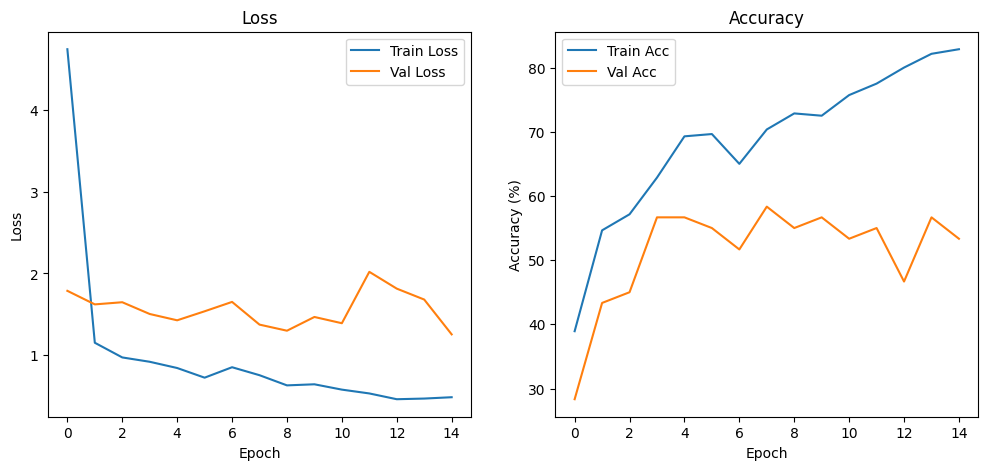

Final Test Accuracy: 0.5500
Final Test Accuracy: 55.00%


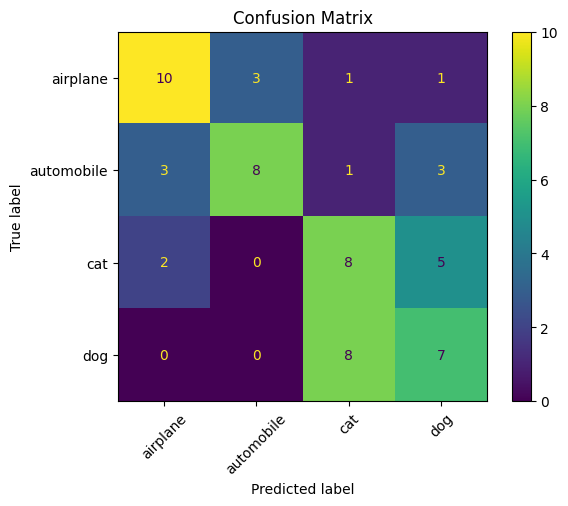

In [ ]:
##############################
# Check GPU availability
##############################

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


##############################
# Define transforms
##############################

# Resize images to 128x128, apply augmentation,
# convert to tensor, and normalize pixel values
transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])


##############################
# Load dataset
##############################

# Load CIFAR-10
dataset = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=transform
)


# Split dataset into train (70%), validation (15%), and test (15%)
selected_classes = {
    "airplane": 0,
    "automobile": 1,
    "cat": 3,
    "dog": 5
}

class_mapping = {
    0: 0,  # airplane
    1: 1,  # automobile
    3: 2,  # cat
    5: 3   # dog
}


train_indices = []
val_indices = []
test_indices = []

generator = torch.Generator().manual_seed(42)


# Select 100 images from each class and split 70/15/15
for class_name, class_id in selected_classes.items():

    class_indices = [
        i for i, label in enumerate(dataset.targets)
        if label == class_id
    ]

    # Randomly select and shuffle 100 images
    class_indices = torch.tensor(class_indices)[
        torch.randperm(len(class_indices), generator=generator)
    ].tolist()[:100]

    # 70 train, 15 validation, 15 test
    train_indices.extend(class_indices[:70])
    val_indices.extend(class_indices[70:85])
    test_indices.extend(class_indices[85:100])


train_data = torch.utils.data.Subset(dataset, train_indices)
val_data = torch.utils.data.Subset(dataset, val_indices)
test_data = torch.utils.data.Subset(dataset, test_indices)


##############################
# DataLoaders
##############################

# pin_memory improves CPU -> GPU transfer when CUDA is available
pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_data,
    batch_size=16,
    shuffle=True,
    pin_memory=pin_memory
)

val_loader = DataLoader(
    val_data,
    batch_size=16,
    shuffle=False,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    test_data,
    batch_size=16,
    shuffle=False,
    pin_memory=pin_memory
)


# Print class names
classes = list(selected_classes.keys())

print("Classes:", classes)
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))


##############################
# Define CNN model
##############################

class SmallCNN(nn.Module):

    def __init__(self):
        super(SmallCNN, self).__init__()

        # Feature extractor: 3 convolutional blocks
        self.features = nn.Sequential(

            nn.Conv2d(
                3, 32, 3, padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                32, 64, 3, padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                64, 128, 3, padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        # Classifier head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*16*16, 128),
            nn.ReLU(),
            nn.Linear(128, len(classes))
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Create model and move it to GPU
net = SmallCNN().to(device)

print("Model device:", next(net.parameters()).device)


##############################
# Loss & Optimizer
##############################

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    net.parameters(),
    lr=0.001
)


##############################
# Training loop
##############################

train_losses, val_losses = [], []
train_accs, val_accs = [], []


for epoch in range(15):

    ##############################
    # Training
    ##############################

    net.train()

    correct = 0
    total = 0
    running_loss = 0

    for inputs, labels in train_loader:

        # Move images to GPU
        inputs = inputs.to(
            device,
            non_blocking=True
        )

        # Convert original CIFAR labels to
        # our four-class labels
        labels = torch.tensor(
            [class_mapping[int(label)] for label in labels],
            dtype=torch.long
        )

        # Move labels to GPU
        labels = labels.to(
            device,
            non_blocking=True
        )

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = net(inputs)

        # Compute loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Track loss
        running_loss += loss.item()

        # Predictions
        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()


    train_losses.append(
        running_loss / len(train_loader)
    )

    train_accs.append(
        100. * correct / total
    )


    ##############################
    # Validation
    ##############################

    net.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in val_loader:

            # Move inputs to GPU
            inputs = inputs.to(
                device,
                non_blocking=True
            )

            # Convert labels
            labels = torch.tensor(
                [class_mapping[int(label)] for label in labels],
                dtype=torch.long
            )

            # Move labels to GPU
            labels = labels.to(
                device,
                non_blocking=True
            )

            # Forward pass
            outputs = net(inputs)

            # Loss
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            # Predictions
            _, predicted = outputs.max(1)

            val_total += labels.size(0)

            val_correct += predicted.eq(
                labels
            ).sum().item()


    val_losses.append(
        val_loss / len(val_loader)
    )

    val_accs.append(
        100. * val_correct / val_total
    )


    print(
        f"Epoch {epoch+1}: "
        f"Train Loss {train_losses[-1]:.4f}, "
        f"Train Acc {train_accs[-1]:.2f}%, "
        f"Val Loss {val_losses[-1]:.4f}, "
        f"Val Acc {val_accs[-1]:.2f}%"
    )


##############################
# Plot Loss & Accuracy
##############################

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    train_losses,
    label='Train Loss'
)

plt.plot(
    val_losses,
    label='Val Loss'
)

plt.legend()
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")


plt.subplot(1,2,2)

plt.plot(
    train_accs,
    label='Train Acc'
)

plt.plot(
    val_accs,
    label='Val Acc'
)

plt.legend()
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.show()


##############################
# Test evaluation
##############################

y_true = []
y_pred = []

net.eval()

with torch.no_grad():

    for inputs, labels in test_loader:

        # Move inputs to GPU
        inputs = inputs.to(
            device,
            non_blocking=True
        )

        # Convert labels
        labels = torch.tensor(
            [class_mapping[int(label)] for label in labels],
            dtype=torch.long
        )

        # Move labels to GPU
        labels = labels.to(
            device,
            non_blocking=True
        )

        # Forward pass
        outputs = net(inputs)

        # Predictions
        _, predicted = outputs.max(1)

        # Move results back to CPU
        y_true.extend(
            labels.cpu().numpy()
        )

        y_pred.extend(
            predicted.cpu().numpy()
        )


##############################
# Final test accuracy
##############################

acc = sum(
    p == t
    for p, t in zip(y_pred, y_true)
) / len(y_true)

print(
    f"Final Test Accuracy: {acc:.4f}"
)

print(
    f"Final Test Accuracy: {acc*100:.2f}%"
)


##############################
# Confusion matrix
##############################

cm = confusion_matrix(
    y_true,
    y_pred
)

ConfusionMatrixDisplay(
    cm,
    display_labels=classes
).plot(
    xticks_rotation=45
)

plt.title("Confusion Matrix")
plt.show()


The model begins to overfit after around 5 to 6 epochs, when training accuracy
continues to improve while validation accuracy stops improving consistently and begins to fluctuate.
The confusion matrix shows that the model was mostly often confusing cats and dogs, which makes visual sense because they share similar textures, shapes, and poses.

**Task 2. Transfer learning on your own dataset**

**Data Source:**  
Images were collected by author and are free for academic use  
visal rengan. (2026). dataset of bike, car, cat, dog. [Dataset]. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/14807807

In [ ]:

def export_finetuned_model(model, filename="mobilenet_finetuned.pth"):
  '''
  Saves and downloads a  fine-tuned-model
  '''
    # Save the model weights
    torch.save(model.state_dict(), filename)

    # Get file size
    file_size = os.path.getsize(filename) / (1024 * 1024)

    print(f"Model saved as {filename}")
    print(f"File size: {file_size:.2f} MB")
    # Download the model
    files.download(filename)

In [ ]:
##############################
# Check for GPU
##############################
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


##############################
# Data transforms
##############################
# Training transform includes augmentation
transform_train = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

# Validation/test transform excludes augmentation
transform_eval = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

##############################
# Load dataset
##############################
# Assume dataset is already split into train/val/test folders (70/15/15)
train_data = datasets.ImageFolder("dataset/train", transform=transform_train)
val_data   = datasets.ImageFolder("dataset/val", transform=transform_eval)
test_data  = datasets.ImageFolder("dataset/test", transform=transform_eval)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=32, shuffle=False)

classes = train_data.classes
num_classes = len(classes)
print("Classes:", classes)
print("Class mapping:", train_data.class_to_idx)
##############################
# Baseline CNN (from scratch)
##############################
class SmallCNN(nn.Module):
    def __init__(self, num_classes):
        super(SmallCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*28*28, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

##############################
# Training function
##############################
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    train_accs, val_accs = [], []
    start_time = time.time()

    for epoch in range(epochs):
        # Training
        model.train()
        correct, total = 0, 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_acc = 100.*correct/total
        train_accs.append(train_acc)

        # Validation
        model.eval()
        correct, total = 0, 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                _, predicted = outputs.max(1)

                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        val_acc = 100.*correct/total
        val_accs.append(val_acc)

        print(f"Epoch {epoch+1}: Train Acc {train_acc:.2f}%, Val Acc {val_acc:.2f}%")

    elapsed = time.time() - start_time
    return train_accs, val_accs, elapsed

##############################
# Train baseline CNN
##############################
cnn = SmallCNN(num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn.parameters(), lr=0.001)

train_accs, val_accs, cnn_time = train_model(
    cnn,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=10
)

##############################
# Transfer Learning (MobileNetV3-Small)
##############################
# Load pretrained backbone
mobilenet = models.mobilenet_v3_small(pretrained=True)

# Replace classifier head
mobilenet.classifier[3] = nn.Linear(
    mobilenet.classifier[3].in_features,
    num_classes
)

# Freeze backbone
for param in mobilenet.features.parameters():
    param.requires_grad = False

# Move model to GPU if available
mobilenet = mobilenet.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mobilenet.classifier.parameters(), lr=0.001)

train_accs, val_accs, frozen_time = train_model(
    mobilenet,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=10
)

##############################
# Evaluate frozen model
##############################
def test_accuracy(model, test_loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, predicted = outputs.max(1)

            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return 100.*correct/total


cnn_test_acc = test_accuracy(cnn, test_loader)

# Evaluation BEFORE fine-tuning
frozen_test_acc = test_accuracy(mobilenet, test_loader)


##############################
# Fine-tune last block
##############################
# Unfreeze last block
for param in mobilenet.features[-1].parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    mobilenet.parameters(),
    lr=1e-4
)

train_accs, val_accs, finetune_time = train_model(
    mobilenet,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=10
)

# Save fine-tuned model
export_finetuned_model(model=mobilenet, filename='mobilenet_finetuned.pth')
##############################
# Evaluate fine-tuned model
##############################
finetune_test_acc = test_accuracy(mobilenet, test_loader)


##############################
# Comparison table
##############################
print("\nComparison Table")
print("| Model                | Test Accuracy | Training Time (s) |")
print("|----------------------|---------------|-------------------|")
print(f"| Scratch CNN          | {cnn_test_acc:.2f}%       | {cnn_time:.1f} |")
print(f"| Transfer (Frozen)    | {frozen_test_acc:.2f}%       | {frozen_time:.1f} |")
print(f"| Transfer (Fine-tuned)| {finetune_test_acc:.2f}%       | {finetune_time:.1f} |")


Using device: cuda
GPU: Tesla T4
Classes: ['class1', 'class2', 'class3', 'class4']
Class mapping: {'class1': 0, 'class2': 1, 'class3': 2, 'class4': 3}
Epoch 1: Train Acc 38.03%, Val Acc 25.00%
Epoch 2: Train Acc 45.90%, Val Acc 25.00%
Epoch 3: Train Acc 58.36%, Val Acc 31.67%
Epoch 4: Train Acc 60.98%, Val Acc 46.67%
Epoch 5: Train Acc 64.59%, Val Acc 61.67%
Epoch 6: Train Acc 70.16%, Val Acc 60.00%
Epoch 7: Train Acc 70.49%, Val Acc 58.33%
Epoch 8: Train Acc 77.05%, Val Acc 66.67%
Epoch 9: Train Acc 78.03%, Val Acc 65.00%
Epoch 10: Train Acc 81.64%, Val Acc 58.33%
Epoch 1: Train Acc 79.34%, Val Acc 95.00%
Epoch 2: Train Acc 94.10%, Val Acc 93.33%
Epoch 3: Train Acc 95.74%, Val Acc 90.00%
Epoch 4: Train Acc 97.38%, Val Acc 90.00%
Epoch 5: Train Acc 97.38%, Val Acc 96.67%
Epoch 6: Train Acc 96.39%, Val Acc 91.67%
Epoch 7: Train Acc 98.69%, Val Acc 95.00%
Epoch 8: Train Acc 99.02%, Val Acc 98.33%
Epoch 9: Train Acc 99.34%, Val Acc 96.67%
Epoch 10: Train Acc 99.67%, Val Acc 93.33%
Epoch 1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Comparison Table
| Model                | Test Accuracy | Training Time (s) |
|----------------------|---------------|-------------------|
| Scratch CNN          | 70.00%       | 36.6 |
| Transfer (Frozen)    | 98.33%       | 29.3 |
| Transfer (Fine-tuned)| 98.33%       | 29.5 |


**Task 3. Look inside with Grad-CAM**

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


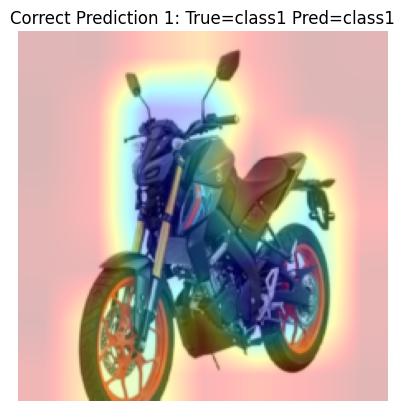

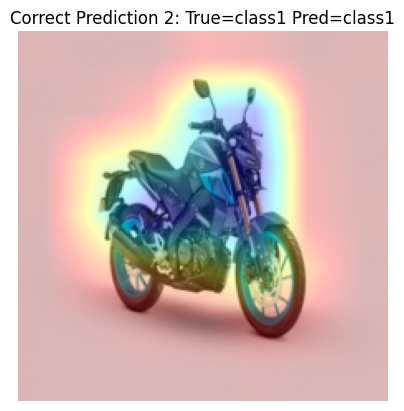

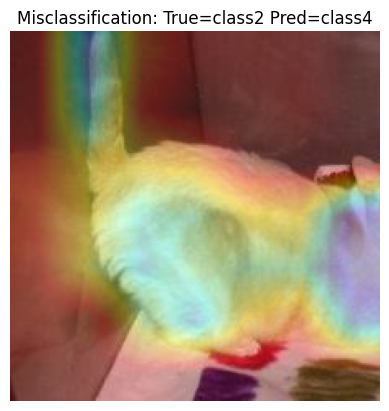

'###############################\n# Grad-CAM class\n##############################\nclass GradCAM:\n    def __init__(self, model, target_layer):\n        self.model = model\n        self.target_layer = target_layer\n        self.gradients = None\n        self.activations = None\n\n        # Register hooks\n        target_layer.register_forward_hook(self.save_activation)\n        target_layer.register_backward_hook(self.save_gradient)\n\n    def save_activation(self, module, input, output):\n        self.activations = output.detach()\n\n    def save_gradient(self, module, grad_input, grad_output):\n        self.gradients = grad_output[0].detach()\n\n    def generate(self, input_tensor, class_idx=None):\n        # Forward pass\n        output = self.model(input_tensor)\n        if class_idx is None:\n            class_idx = output.argmax(dim=1).item()\n\n        # Backward pass\n        self.model.zero_grad()\n        loss = output[0, class_idx]\n        loss.backward()\n\n        # Comp

In [ ]:
###############################
# Grad-CAM class
##############################
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register hooks
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        # Forward pass
        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        # Backward pass
        self.model.zero_grad()
        loss = output[0, class_idx]
        loss.backward()

        # Compute Grad-CAM
        weights = self.gradients.mean(dim=(2,3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)

        cam = torch.nn.functional.interpolate(
            cam,
            size=input_tensor.shape[2:],
            mode='bilinear',
            align_corners=False
        )

        cam = cam.squeeze().cpu().numpy()

        # Normalize
        cam = (cam - cam.min()) / (cam.max() - cam.min())

        return cam


# ##############################
# Overlay function
##############################
import cv2
import numpy as np

def overlay_heatmap(img_tensor, heatmap):
    img = img_tensor.permute(1,2,0).cpu().numpy()
    img = (img - img.min()) / (img.max() - img.min())

    heatmap = cv2.applyColorMap(
        np.uint8(255*heatmap),
        cv2.COLORMAP_JET
    )

    heatmap = np.float32(heatmap)/255

    overlay = heatmap*0.4 + img
    overlay = overlay / overlay.max()

    return overlay


##############################
# Apply Grad-CAM to 3 test images
###############################
# Use last conv block of MobileNetV3-Small from task 2
target_layer = mobilenet.features[-1]
gradcam = GradCAM(mobilenet, target_layer)

correct_examples = []
misclassified_examples = []

# Loop through test set until we find 2 correct and 1 misclassified
mobilenet.eval()

with torch.no_grad():
    for inputs, labels in test_loader:

        # Move data to GPU if available
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = mobilenet(inputs)
        _, preds = outputs.max(1)

        for i in range(len(labels)):

            if preds[i] == labels[i] and len(correct_examples) < 2:
                correct_examples.append(
                    (inputs[i], labels[i], preds[i])
                )

            elif preds[i] != labels[i] and len(misclassified_examples) < 1:
                misclassified_examples.append(
                    (inputs[i], labels[i], preds[i])
                )

        if len(correct_examples) == 2 and len(misclassified_examples) == 1:
            break


# Generate Grad-CAM overlays
examples = correct_examples + misclassified_examples

titles = [
    "Correct Prediction 1",
    "Correct Prediction 2",
    "Misclassification"
]

for idx, (img, true_label, pred_label) in enumerate(examples):

    # Image is already on GPU
    input_tensor = img.unsqueeze(0).to(device)

    heatmap = gradcam.generate(
        input_tensor,
        class_idx=pred_label.item()
    )

    overlay_img = overlay_heatmap(img, heatmap)

    plt.imshow(overlay_img)

    plt.title(
        f"{titles[idx]}: "
        f"True={classes[true_label.item()]} "
        f"Pred={classes[pred_label.item()]}"
    )

    plt.axis("off")
    plt.show()